# Building Age Classification from Satellite Imagery

# Notebook 4 — Modelling & Evaluation

---

**Approach: Metric Learning**

In this notebook we will use a **metric learning** approach to the classification problem. This involves learning a feature representation where
buildings of the same age class cluster together, regardless of which city they come from. 

In practice this means:
1. **Train on Madrid** (the labelled city) using cross-validation to get reliable performance
   estimates with error bars.
2. **Zero-shot transfer** — apply the Madrid model directly to Amsterdam, with no Amsterdam
   labels, to measure the baseline domain gap.
3. **Few-shot prototype transfer** — given a small number of labelled Amsterdam examples,
   compute per-class prototype vectors (class means in feature space) and classify by
   nearest prototype. This is the inference step of prototype networks, a standard
   metric learning technique.

The few-shot experiment shows how much label budget is needed to close the Madrid–Amsterdam gap.

For more information on the metric learning approach, please see the supportind document "METRIC_LEARNING_APPROACH.md"

**NOTE**:  Metric learning is _one possible approach_.  Feel free to try another approach!

## 4.1 Setup & Imports

In [4]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CLASS_LABELS_MADRID    = {1: 'Pre-1960',  2: '1960-1984', 3: '1984-2004', 4: '2004-2024'}
CLASS_LABELS_AMSTERDAM = {1: 'Pre-1945',  2: '1945-1984', 3: '1984-2004', 4: '2004-2024'}

plt.rcParams['figure.dpi'] = 100
print("Setup complete.")


Setup complete.


## 4.2 Load Preprocessed Data

In [2]:
import pickle

with open('../data/held_out_NOT_FOR_PARTICIPANTS/preprocessed/preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X_madrid = data['X_madrid']
y_madrid = data['y_madrid']

X_amsterdam = data['X_amsterdam']

feature_names = data['feature_names']

pixel_ids_madrid = data['pixel_ids_madrid']
pixel_ids_amsterdam = data['pixel_ids_amsterdam']

print(f'Madrid: {X_madrid.shape}')
print(f'Amsterdam: {X_amsterdam.shape}')
print(f'Features: {len(feature_names)}')

Madrid: (76263, 60)
Amsterdam: (25992, 60)
Features: 60


C:\Users\dell\AppData\Roaming\Python\Python315\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [11]:
# 1. Configure 5-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Define the four models

benchmark_models = {

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

print("Four models prepared successfully!")

for name in benchmark_models:
    print("-", name)

print("Cross-validation folds:", cv.get_n_splits())

Four models prepared successfully!
- Logistic Regression
- Random Forest
- Extra Trees
- LightGBM
Cross-validation folds: 5


In [7]:
from sklearn.pipeline import make_pipeline

print("make_pipeline imported successfully!")

make_pipeline imported successfully!


In [10]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [12]:
import pandas as pd

results_df = pd.read_csv("../benchmark_madrid_results.csv")

print(results_df.round(4).to_string(index=False))

              Model  Macro F1 Mean  Macro F1 Std
      Random Forest         0.6266        0.0037
           LightGBM         0.6231        0.0027
        Extra Trees         0.6202        0.0044
Logistic Regression         0.5793        0.0064


In [5]:
%pip install scikit-learn


Defaulting to user installation because normal site-packages is not writeable
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.1 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/8.4 MB 1.2 MB/s eta 0:00:07
   ----- ---------------------------------- 1.0/8.4 MB 1.2 MB/s eta 0:00:06
   ------ --------------------------------- 1.3/8.4 MB 1.2 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.4 MB 1.2 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.4 MB 1.2 MB/s eta 0:


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier

print("All four models are ready!")
print("Scikit-learn:", sklearn.__version__)
print("LightGBM:", lgb.__version__)

All four models are ready!
Scikit-learn: 1.9.1
LightGBM: 4.7.0


---

## 4.3 Cross-Validation on Madrid

### What is a fold?

The training data is randomly divided into **k equal parts** called folds. The model is
trained on k-1 folds and evaluated on the remaining 1 fold. This is repeated k times,
rotating which fold is held out each time, so every sample is evaluated exactly once.
The result is k performance scores, one per fold.

### What is a repeat?

A **repeat** runs the entire k-fold process again with a fresh random split of the data
into folds. The second repeat produces k more scores that are independent of the first
repeat (different samples end up in different folds). With r repeats you collect k x r
scores in total.

### Why repeats matter for variance estimation

The k scores within a single repeat are **not independent** — every pair of folds shares
(k-2)/k of their training data. This correlation means the empirical standard deviation
of k scores underestimates the true run-to-run variance. A single 5-fold run gives only
5 correlated numbers, which is a very noisy basis for a variance estimate.

Adding repeats breaks this correlation: scores from different repeats are independent
because the splits are drawn fresh each time. Even 5 repeats (25 scores total) gives a
much more reliable standard deviation than a single 5-fold run.

### Configuration

Set `N_FOLDS, N_REPEATS` below. The default `5, 1` reproduces standard 5-fold CV.
Increase repeats (e.g. `10, 5`) for a more reliable variance estimate at the cost of
additional training time — each repeat requires k more model fits.

In [13]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import RepeatedStratifiedKFold
# ── Configuration: set both values here ───────────────────────────────────────
N_FOLDS, N_REPEATS = 5, 5
# ─────────────────────────────────────────────────────────────────────────────

RF_PARAMS   = dict(n_estimators=500, class_weight='balanced', random_state=42, n_jobs=-1)
total_fits  = N_FOLDS * N_REPEATS
rskf        = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=42)

all_f1      = []
oof_true    = []
oof_pred    = []
oof_proba   = []   # predict_proba output for each held-out pixel
oof_indices = []   # original row index of each held-out pixel

print(f'{N_FOLDS}-fold x {N_REPEATS}-repeat CV on Madrid  ({total_fits} model fits)')
print('-' * 55)

for fit_num, (tr_idx, val_idx) in enumerate(rskf.split(X_madrid, y_madrid), 1):
    X_tr, X_val = X_madrid[tr_idx], X_madrid[val_idx]
    y_tr, y_val = y_madrid[tr_idx], y_madrid[val_idx]

    rf = RandomForestClassifier(**RF_PARAMS)
    rf.fit(X_tr, y_tr)
    y_pred  = rf.predict(X_val)
    y_proba = rf.predict_proba(X_val)

    oof_true.extend(y_val.tolist())
    oof_pred.extend(y_pred.tolist())
    oof_proba.extend(y_proba.tolist())
    oof_indices.extend(val_idx.tolist())

    f1 = f1_score(y_val, y_pred, average='macro')
    all_f1.append(f1)
    print(f'  Fit {fit_num:3d}/{total_fits}: macro-F1 = {f1:.4f}')

print('-' * 55)
print(f'  Mean macro F1: {np.mean(all_f1):.4f} +/- {np.std(all_f1):.4f}')

fold_f1     = all_f1
oof_true    = np.array(oof_true)
oof_pred    = np.array(oof_pred)
oof_proba   = np.array(oof_proba)
oof_indices = np.array(oof_indices)


5-fold x 5-repeat CV on Madrid  (25 model fits)
-------------------------------------------------------
  Fit   1/25: macro-F1 = 0.6277
  Fit   2/25: macro-F1 = 0.6363
  Fit   3/25: macro-F1 = 0.6295
  Fit   4/25: macro-F1 = 0.6235
  Fit   5/25: macro-F1 = 0.6231
  Fit   6/25: macro-F1 = 0.6220
  Fit   7/25: macro-F1 = 0.6328
  Fit   8/25: macro-F1 = 0.6307
  Fit   9/25: macro-F1 = 0.6286
  Fit  10/25: macro-F1 = 0.6245
  Fit  11/25: macro-F1 = 0.6235
  Fit  12/25: macro-F1 = 0.6351
  Fit  13/25: macro-F1 = 0.6272
  Fit  14/25: macro-F1 = 0.6346
  Fit  15/25: macro-F1 = 0.6239
  Fit  16/25: macro-F1 = 0.6298
  Fit  17/25: macro-F1 = 0.6299
  Fit  18/25: macro-F1 = 0.6205
  Fit  19/25: macro-F1 = 0.6284
  Fit  20/25: macro-F1 = 0.6268
  Fit  21/25: macro-F1 = 0.6319
  Fit  22/25: macro-F1 = 0.6292
  Fit  23/25: macro-F1 = 0.6334
  Fit  24/25: macro-F1 = 0.6267
  Fit  25/25: macro-F1 = 0.6237
-------------------------------------------------------
  Mean macro F1: 0.6281 +/- 0.0043


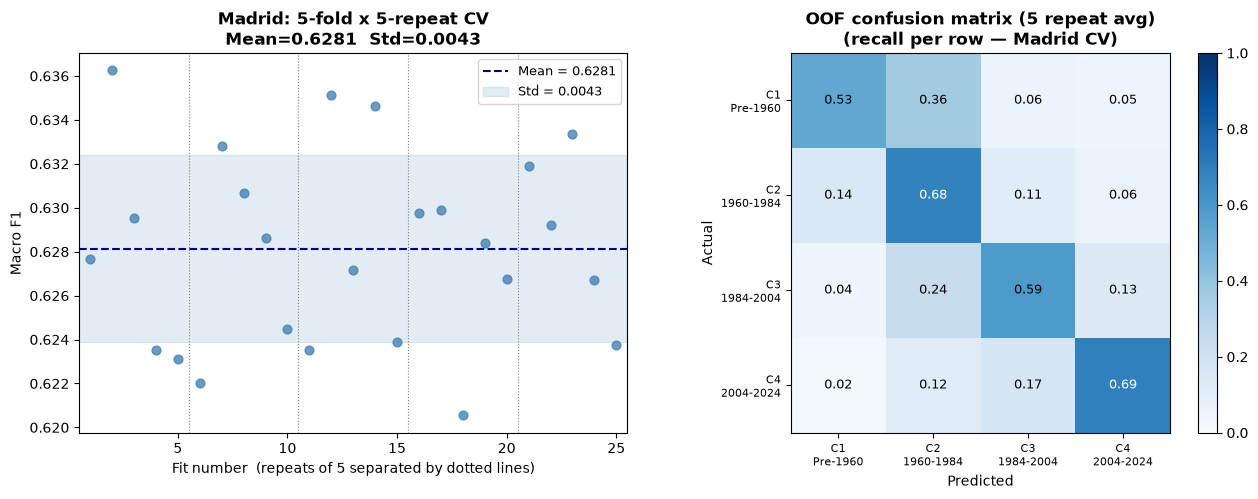

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

CLASS_LABELS_MADRID = {
    1: 'Pre-1960',
    2: '1960-1984',
    3: '1984-2004',
    4: '2004-2024'
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: individual scores + mean/std band
ax   = axes[0]
xs   = np.arange(1, total_fits + 1)
mn   = np.mean(all_f1)
sd   = np.std(all_f1)

ax.scatter(xs, all_f1, color='steelblue', s=40, zorder=3, alpha=0.8)
ax.axhline(mn, color='navy', linewidth=1.5, linestyle='--', label=f'Mean = {mn:.4f}')
ax.fill_between([0.5, total_fits + 0.5], mn - sd, mn + sd,
                color='steelblue', alpha=0.15, label=f'Std = {sd:.4f}')

# Mark repeat boundaries
if N_REPEATS > 1:
    for r in range(1, N_REPEATS):
        ax.axvline(r * N_FOLDS + 0.5, color='grey', linewidth=0.8, linestyle=':')
    ax.set_xlabel(f'Fit number  (repeats of {N_FOLDS} separated by dotted lines)')
else:
    ax.set_xlabel('Fold')

ax.set_ylabel('Macro F1')
ax.set_title(f'Madrid: {N_FOLDS}-fold x {N_REPEATS}-repeat CV\n'
             f'Mean={mn:.4f}  Std={sd:.4f}', fontweight='bold')
ax.set_xlim(0.5, total_fits + 0.5)
ax.legend(fontsize=9)

# Right: out-of-fold confusion matrix (accumulated over all folds x repeats)
ax = axes[1]
classes_mad = sorted(np.unique(oof_true))
cm_oof  = confusion_matrix(oof_true, oof_pred, labels=classes_mad)
cm_norm = cm_oof.astype(float) / cm_oof.sum(axis=1, keepdims=True)
xlbls   = [f'C{c}\n{CLASS_LABELS_MADRID[c]}' for c in classes_mad]
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(classes_mad))); ax.set_xticklabels(xlbls, fontsize=8)
ax.set_yticks(range(len(classes_mad))); ax.set_yticklabels(xlbls, fontsize=8)
for i in range(len(classes_mad)):
    for j in range(len(classes_mad)):
        v = cm_norm[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if v > 0.6 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
title_suffix = f'({N_REPEATS} repeat avg)' if N_REPEATS > 1 else ''
ax.set_title(f'OOF confusion matrix {title_suffix}\n(recall per row — Madrid CV)',
             fontweight='bold')
plt.colorbar(im, ax=ax)

plt.tight_layout()

fig.savefig(
    "../madrid_cv_25_fits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

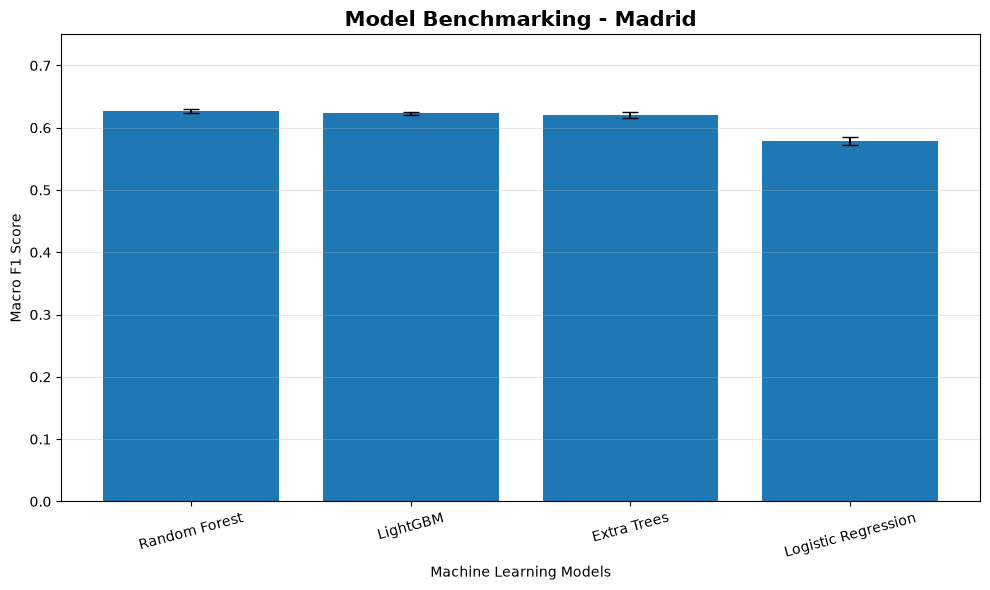

Comparison chart saved successfully!


In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Macro F1 Mean"],
    yerr=results_df["Macro F1 Std"],
    capsize=6
)

plt.title(
    "Model Benchmarking - Madrid",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Macro F1 Score")

plt.ylim(0, 0.75)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save presentation-quality image
plt.savefig(
    "../benchmark_madrid_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison chart saved successfully!")

We see that the macro F1 determination is accurate to within roughly plus or minus 0.01. The confusion matrix shows that Classes 2 and 4 acheive higher recall than the other classes.  We also see that Class 2 is over-predicted.  For example, mmost instances of class 1 are predicted as class 2. This is a strong indication that the class imbalance is biasing prediction towards class 2, which is hte largest class.

In [22]:
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Predict Amsterdam using the Madrid-trained model
predictions = rf_final.predict(X_amsterdam)
probabilities = rf_final.predict_proba(X_amsterdam)

# 2. Calculate confidence
confidence = probabilities.max(axis=1)

# 3. Calculate uncertainty (Shannon Entropy)
entropy = -(
    probabilities *
    np.log2(np.clip(probabilities, 1e-12, 1.0))
).sum(axis=1)

# 4. Create results table
amsterdam_results = pd.DataFrame({
    "building_index": np.arange(len(predictions)),
    "pixel_x": pixel_ids_amsterdam[:, 0],
    "pixel_y": pixel_ids_amsterdam[:, 1],
    "predicted_class": predictions,
    "confidence": confidence,
    "entropy": entropy
})

# 5. Add probabilities for all four classes
for i, cls in enumerate(rf_final.classes_):
    amsterdam_results[f"probability_class_{cls}"] = probabilities[:, i]

# 6. Save CSV in the project folder
output_path = Path("../amsterdam_predictions_provisional.csv")

amsterdam_results.to_csv(output_path, index=False)

print("Amsterdam predictions saved successfully!")
print("Total buildings:", len(amsterdam_results))
print("Total columns:", len(amsterdam_results.columns))
print("File location:", output_path.resolve())

print("\nFirst 5 predictions:")
print(amsterdam_results.head().to_string(index=False))

Amsterdam predictions saved successfully!
Total buildings: 25992
Total columns: 10
File location: C:\Users\dell\Desktop\data_hack2\amsterdam_predictions_provisional.csv

First 5 predictions:
 building_index  pixel_x  pixel_y  predicted_class  confidence  entropy  probability_class_1  probability_class_2  probability_class_3  probability_class_4
              0    20600   193589                4       0.688 1.368090                0.064                0.106                0.142                0.688
              1    20600   193590                4       0.586 1.622678                0.100                0.154                0.160                0.586
              2    20601   193591                4       0.700 1.311799                0.052                0.086                0.162                0.700
              3    20601   193593                4       0.518 1.629235                0.036                0.232                0.214                0.518
              4    20602   19

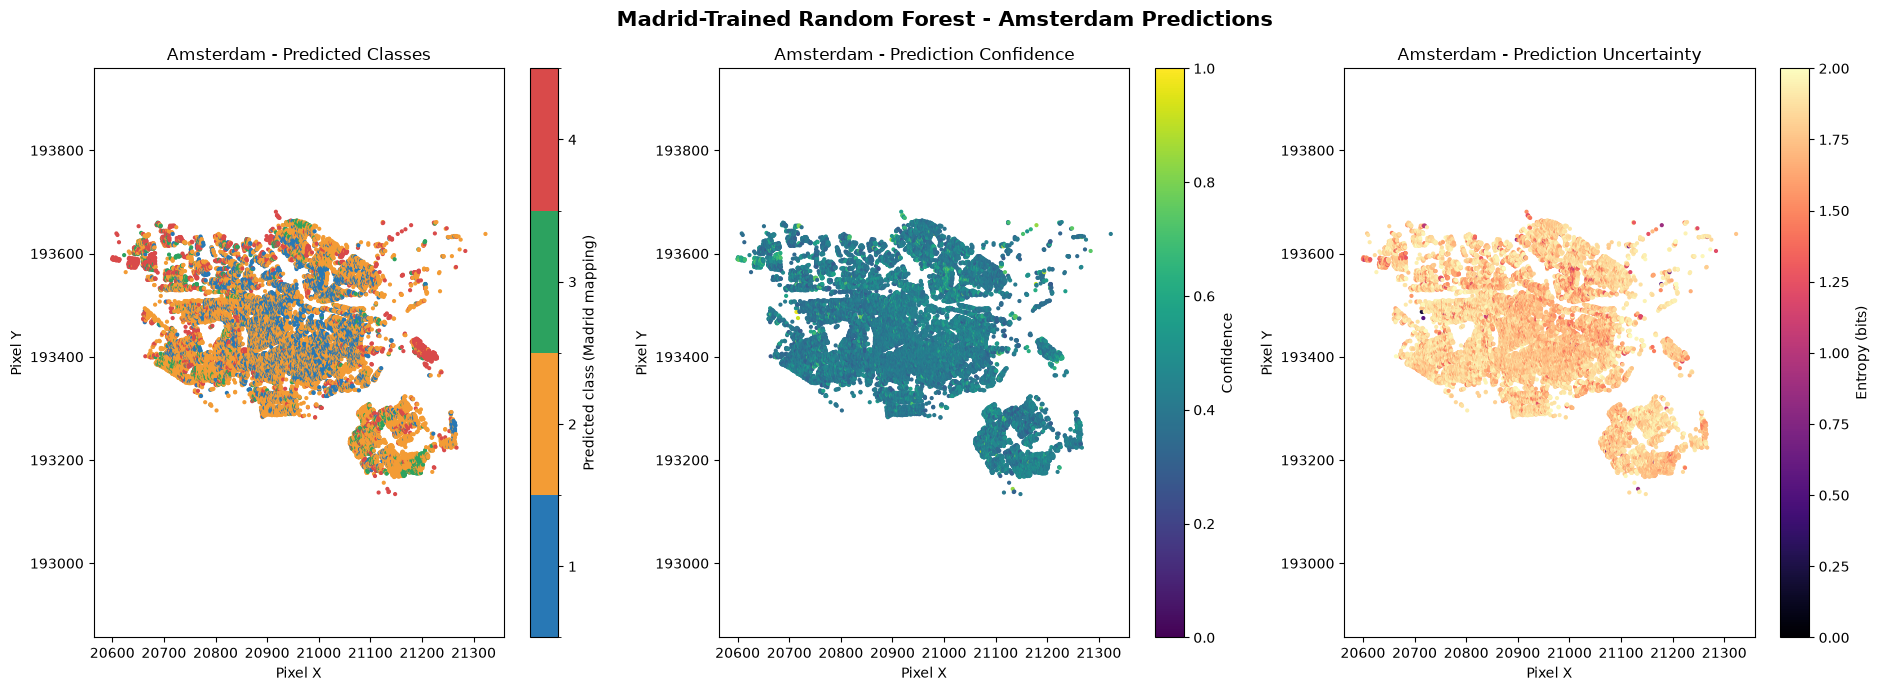

Amsterdam prediction maps saved successfully!


In [23]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Class colors
class_cmap = ListedColormap([
    '#2878B5',
    '#F39C35',
    '#2CA25F',
    '#D94A4A'
])

class_norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5],
    class_cmap.N
)

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

# 1. Predicted age classes
p1 = axes[0].scatter(
    pixel_ids_amsterdam[:, 0],
    pixel_ids_amsterdam[:, 1],
    c=predictions,
    cmap=class_cmap,
    norm=class_norm,
    s=4
)

axes[0].set_title("Amsterdam - Predicted Classes")
axes[0].set_xlabel("Pixel X")
axes[0].set_ylabel("Pixel Y")

cbar1 = plt.colorbar(p1, ax=axes[0], ticks=[1, 2, 3, 4])
cbar1.set_label("Predicted class (Madrid mapping)")

# 2. Confidence map
p2 = axes[1].scatter(
    pixel_ids_amsterdam[:, 0],
    pixel_ids_amsterdam[:, 1],
    c=confidence,
    cmap="viridis",
    vmin=0,
    vmax=1,
    s=4
)

axes[1].set_title("Amsterdam - Prediction Confidence")
axes[1].set_xlabel("Pixel X")
axes[1].set_ylabel("Pixel Y")

plt.colorbar(p2, ax=axes[1], label="Confidence")

# 3. Uncertainty map
p3 = axes[2].scatter(
    pixel_ids_amsterdam[:, 0],
    pixel_ids_amsterdam[:, 1],
    c=entropy,
    cmap="magma",
    vmin=0,
    vmax=2,
    s=4
)

axes[2].set_title("Amsterdam - Prediction Uncertainty")
axes[2].set_xlabel("Pixel X")
axes[2].set_ylabel("Pixel Y")

plt.colorbar(p3, ax=axes[2], label="Entropy (bits)")

for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")

plt.suptitle(
    "Madrid-Trained Random Forest - Amsterdam Predictions",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../amsterdam_prediction_maps_provisional.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Amsterdam prediction maps saved successfully!")

In [24]:
print("AMSTERDAM PREDICTIONS QUALITY CHECK")
print("-" * 45)

print("Total buildings:", len(amsterdam_results))

print("Missing values:",
      amsterdam_results.isnull().sum().sum())

print("Probability sums:",
      np.allclose(
          probabilities.sum(axis=1),
          1.0,
          atol=1e-6
      ))

print("Confidence range:",
      round(confidence.min(), 4),
      "-",
      round(confidence.max(), 4))

print("Entropy range:",
      round(entropy.min(), 4),
      "-",
      round(entropy.max(), 4))

print("\nPredictions per class:")
print(amsterdam_results["predicted_class"].value_counts().sort_index())

print("\nQuality check completed!")

AMSTERDAM PREDICTIONS QUALITY CHECK
---------------------------------------------
Total buildings: 25992
Missing values: 0
Probability sums: True
Confidence range: 0.256 - 0.98
Entropy range: 0.1719 - 1.9997

Predictions per class:
predicted_class
1     6895
2    14789
3     1629
4     2679
Name: count, dtype: int64

Quality check completed!


---

## 4.3a  Spatial Uncertainty Mapping

### `predict_proba` and per-pixel confidence

`RandomForestClassifier.predict_proba(X)` returns a **probability vector** $(p_1, p_2, p_3, p_4)$ for each pixel, where $p_k$ is the fraction of trees in the forest that voted for class $k$.  These values sum to 1, and the hard label produced by `predict()` is simply $\arg\max_k p_k$.

Using `predict_proba` gives a richer picture than a single label: a pixel with probabilities $(0.90, 0.05, 0.03, 0.02)$ is confidently assigned to class 1, while $(0.30, 0.28, 0.25, 0.17)$ is a near-random guess that happens to land on class 1.  The two pixels look identical in a confusion matrix but carry very different levels of certainty.

### Mapping uncertainty across the city

We use `predict_proba` to study the **geographical distribution of uncertainty** — where in the city is the model confident, and where is it unsure?  Mapping uncertainty back onto the building grid can reveal:

- Clusters of uncertain pixels along age-class boundaries or in mixed-use districts
- Areas where the domain gap (Madrid→Amsterdam) inflates uncertainty systematically
- Neighbourhoods where targeted labelling would most improve performance

Two complementary measures are shown for each city:

| Measure | Formula | Interpretation |
|---------|---------|----------------|
| **Shannon entropy** | $H = -\sum_k p_k \log_2 p_k$ (bits) | Ranges from 0 (all probability on one class) to 2 bits (uniform over 4 classes).  High = uncertain classifier. |
| **KL from true class** | $D = -\log_2 p_{\text{true}}$ (bits) | The KL divergence of the predicted distribution from the true one-hot distribution simplifies to the negative log-probability of the correct class.  **0 = model was certain and correct; high = wrong or uncertain.**  Colour scale is inverted so bright = accurate. |

Unique Madrid pixels: 76263
Predictions per pixel: 5 - 5


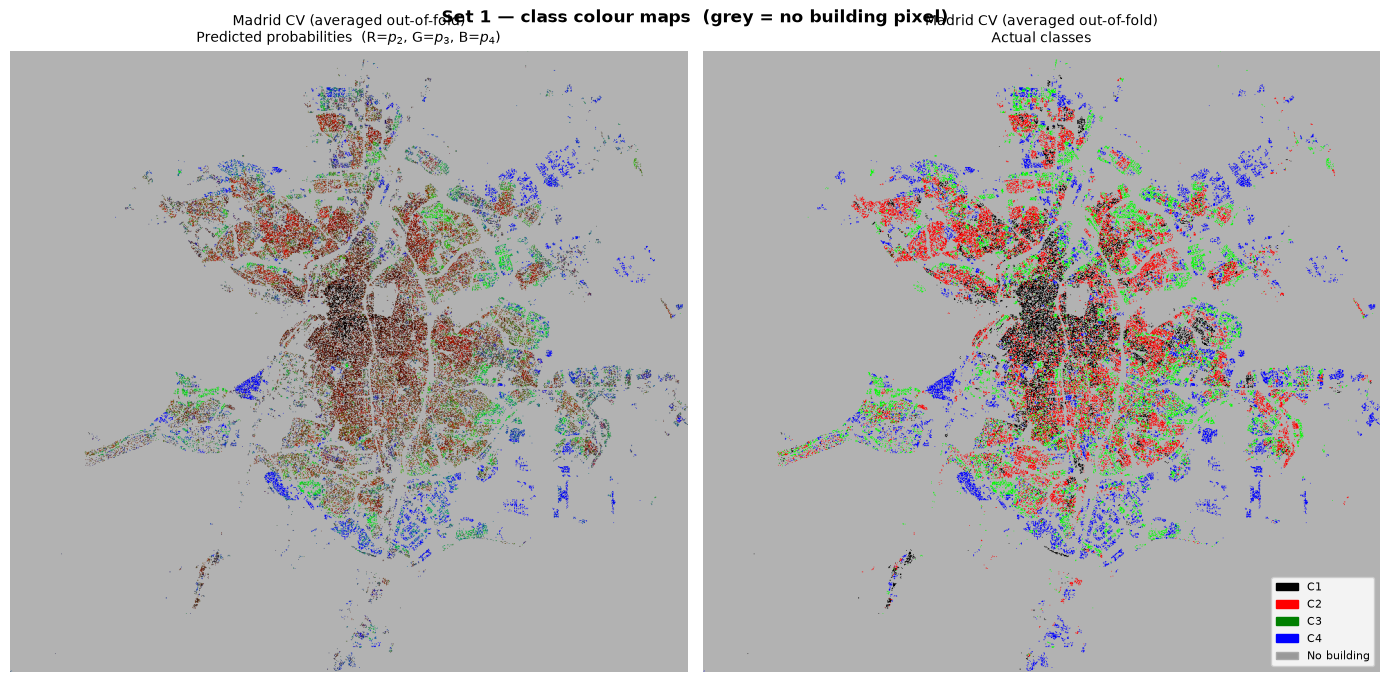

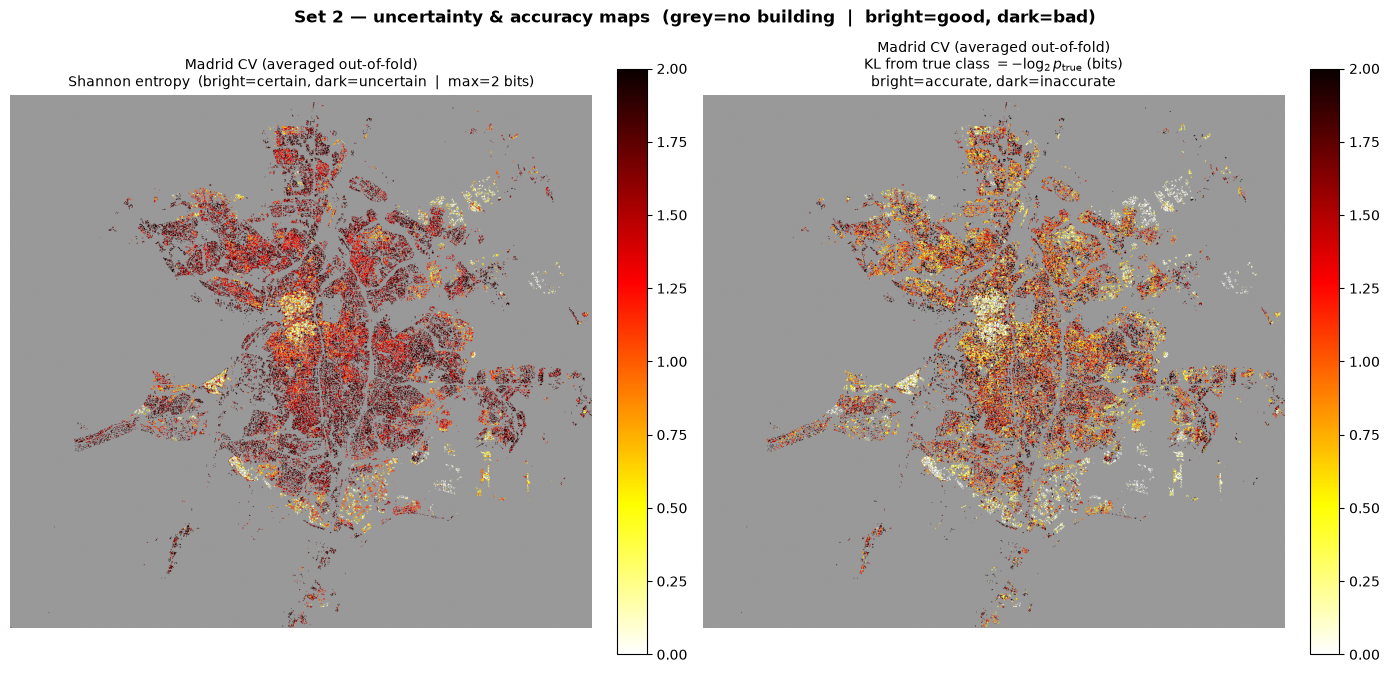

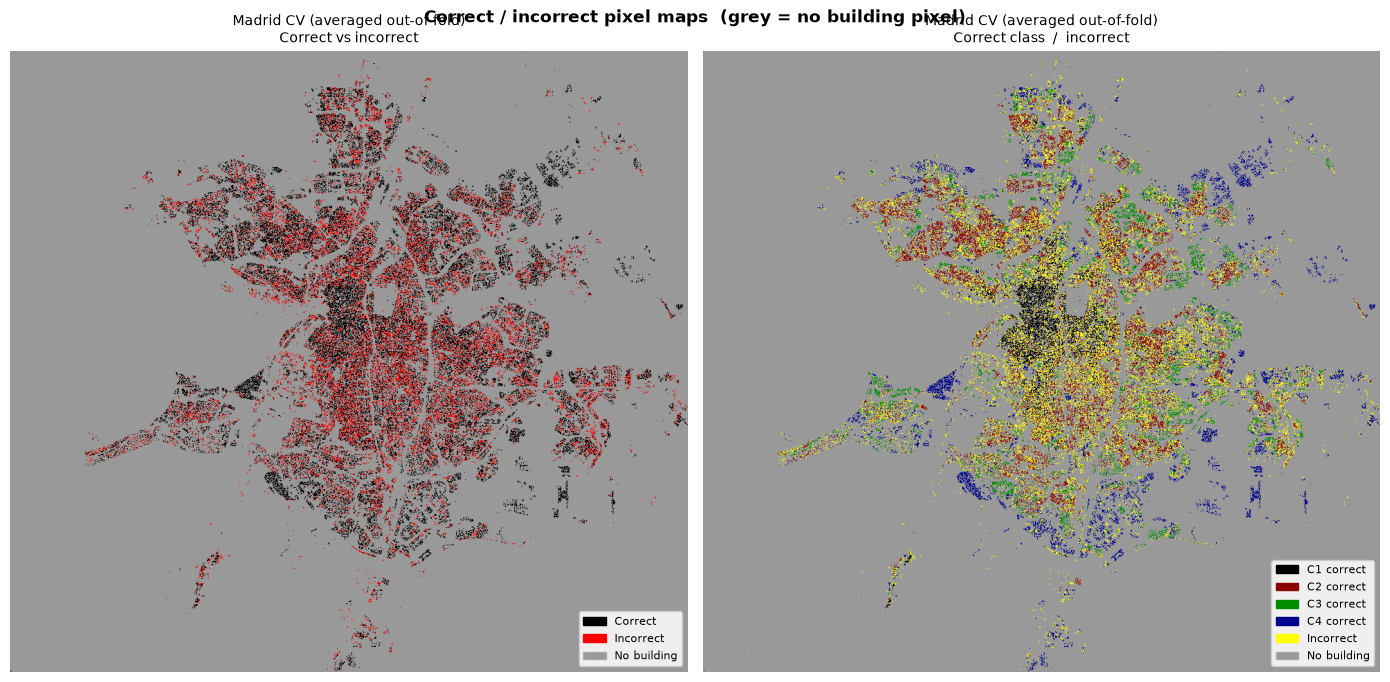

In [15]:
import matplotlib.patches as mpatches

_GREY    = (0.6, 0.6, 0.6)
_NO_BLDG = mpatches.Patch(facecolor=_GREY, edgecolor='darkgrey', label='No building')


def make_pixel_grid(pixel_ids, values, fill_value):
    """Place per-pixel values into a 2-D spatial image using (px_key, py_key) coordinates.
    values: (N,) scalar or (N, C) multi-channel array.
    fill_value: value for grid positions with no building pixel.
    """
    px = pixel_ids[:, 0].astype(int);  px -= px.min()
    py = pixel_ids[:, 1].astype(int);  py -= py.min()
    H, W = py.max() + 1, px.max() + 1
    if values.ndim == 1:
        img = np.full((H, W), fill_value, dtype=np.float32)
        img[py, px] = values
    else:
        img = np.full((H, W, values.shape[1]), fill_value, dtype=np.float32)
        img[py, px] = values
    return img


def spatial_uncertainty_plots(pixel_ids, proba, y_true, title_prefix=''):
    """
    Set 1 (grey background):
        Left : RGB image where R=p2*256, G=p3*256, B=p4*256
        Right: actual class colours  (C1=black, C2=red, C3=green, C4=blue)
    Set 2 (hot_r — bright=good, dark=bad):
        Left : Shannon entropy in bits  (bright=certain, dark=uncertain)
        Right: KL(true||pred) = -log2(p_true_class)  (bright=accurate, dark=inaccurate)
    """
    eps = 1e-10

    # ── Set 1: colour images ──────────────────────────────────────────────────
    rgb_vals = (np.floor(proba[:, 1:] * 256).clip(0, 255) / 255.0).astype(np.float32)
    rgb_img  = make_pixel_grid(pixel_ids, rgb_vals, fill_value=0.70)

    _class_rgb = np.array([[0,0,0],[1,0,0],[0,1,0],[0,0,1]], dtype=np.float32)
    cls_img    = make_pixel_grid(pixel_ids, _class_rgb[y_true - 1], fill_value=0.7)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(rgb_img);  axes[0].axis('off')
    axes[0].set_title(f'{title_prefix}\nPredicted probabilities  '
                      r'(R=$p_2$, G=$p_3$, B=$p_4$)', fontsize=10)

    axes[1].imshow(cls_img);  axes[1].axis('off')
    axes[1].set_title(f'{title_prefix}\nActual classes', fontsize=10)
    axes[1].legend(handles=[
        mpatches.Patch(color='black', label='C1'),
        mpatches.Patch(color='red',   label='C2'),
        mpatches.Patch(color='green', label='C3'),
        mpatches.Patch(color='blue',  label='C4'),
        _NO_BLDG,
    ], loc='lower right', fontsize=8, framealpha=0.85)

    plt.suptitle('Set 1 — class colour maps  (grey = no building pixel)',
                 fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ── Set 2: uncertainty / accuracy maps ────────────────────────────────────
    H_vals           = -(proba * np.log2(proba + eps)).sum(axis=1)
    true_class_proba = proba[np.arange(len(y_true)), y_true - 1]
    kl_vals          = -np.log2(true_class_proba + eps)

    H_img  = make_pixel_grid(pixel_ids, H_vals.astype(np.float32),  fill_value=np.nan)
    kl_img = make_pixel_grid(pixel_ids, kl_vals.astype(np.float32), fill_value=np.nan)

    cmap_h  = plt.cm.hot_r.copy(); cmap_h.set_bad(_GREY)
    cmap_kl = plt.cm.hot_r.copy(); cmap_kl.set_bad(_GREY)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    im0 = axes[0].imshow(H_img, cmap=cmap_h, vmin=0, vmax=2)
    axes[0].axis('off')
    axes[0].set_title(f'{title_prefix}\nShannon entropy  '
                      '(bright=certain, dark=uncertain  |  max=2 bits)', fontsize=10)
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    im1 = axes[1].imshow(kl_img, cmap=cmap_kl, vmin=0, vmax=2)
    axes[1].axis('off')
    axes[1].set_title(f'{title_prefix}\n'
                      r'KL from true class $= -\log_2 p_{\rm true}$ (bits)'
                      '\nbright=accurate, dark=inaccurate', fontsize=10)
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    plt.suptitle('Set 2 — uncertainty & accuracy maps  '
                 '(grey=no building  |  bright=good, dark=bad)', fontweight='bold')
    plt.tight_layout()
    plt.show()


def spatial_accuracy_plots(pixel_ids, y_true, y_pred, title_prefix=''):
    """
    Plot 1: black=correct, red=incorrect.
    Plot 2: C1=black, C2=mid-dark red, C3=mid-dark green, C4=mid-dark blue, incorrect=yellow.
    Grey background on both.
    """
    correct = (y_true == y_pred)

    p1_vals = np.where(
        correct[:, None],
        np.array([[0, 0, 0]], dtype=np.float32),
        np.array([[1, 0, 0]], dtype=np.float32),
    )
    p1_img = make_pixel_grid(pixel_ids, p1_vals, fill_value=0.6)

    correct_colors = np.array([
        [  0,   0,   0],
        [140,   0,   0],
        [  0, 140,   0],
        [  0,   0, 140],
    ], dtype=np.float32) / 255.0
    yellow  = np.array([[1, 1, 0]], dtype=np.float32)
    p2_vals = np.where(correct[:, None], correct_colors[y_true - 1], yellow)
    p2_img  = make_pixel_grid(pixel_ids, p2_vals.astype(np.float32), fill_value=0.6)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(p1_img);  axes[0].axis('off')
    axes[0].set_title(f'{title_prefix}\nCorrect vs incorrect', fontsize=10)
    axes[0].legend(handles=[
        mpatches.Patch(color='black', label='Correct'),
        mpatches.Patch(color='red',   label='Incorrect'),
        _NO_BLDG,
    ], loc='lower right', fontsize=8, framealpha=0.85)

    axes[1].imshow(p2_img);  axes[1].axis('off')
    axes[1].set_title(f'{title_prefix}\nCorrect class  /  incorrect', fontsize=10)
    axes[1].legend(handles=[
        mpatches.Patch(color='black',                      label='C1 correct'),
        mpatches.Patch(color=(140/255, 0,       0      ),  label='C2 correct'),
        mpatches.Patch(color=(0,       140/255, 0      ),  label='C3 correct'),
        mpatches.Patch(color=(0,       0,       140/255),  label='C4 correct'),
        mpatches.Patch(color='yellow',                     label='Incorrect'),
        _NO_BLDG,
    ], loc='lower right', fontsize=8, framealpha=0.85)

    plt.suptitle('Correct / incorrect pixel maps  (grey = no building pixel)',
                 fontweight='bold')
    plt.tight_layout()
    plt.show()


# ── Madrid OOF: average predictions across repeats ──

unique_idx = np.unique(oof_indices)

positions = np.searchsorted(unique_idx, oof_indices)

proba_sum = np.zeros(
    (len(unique_idx), oof_proba.shape[1]),
    dtype=np.float64
)

counts = np.zeros(len(unique_idx), dtype=np.int32)

np.add.at(proba_sum, positions, oof_proba)
np.add.at(counts, positions, 1)

if not np.all(counts == N_REPEATS):
    raise ValueError("Unexpected number of predictions per pixel.")

oof_proba_avg = proba_sum / counts[:, None]

y_true_map = y_madrid[unique_idx]
y_pred_avg = np.argmax(oof_proba_avg, axis=1) + 1

pixel_ids_map = pixel_ids_madrid[unique_idx]

print("Unique Madrid pixels:", len(unique_idx))
print("Predictions per pixel:", counts.min(), "-", counts.max())

spatial_uncertainty_plots(
    pixel_ids_map,
    oof_proba_avg,
    y_true_map,
    title_prefix='Madrid CV (averaged out-of-fold)'
)

spatial_accuracy_plots(
    pixel_ids_map,
    y_true_map,
    y_pred_avg,
    title_prefix='Madrid CV (averaged out-of-fold)'
)

We can see that despite the relatively low accuracy rates, the algorithm seems to be correctly identifying the major local areas where each class dominates. this suggests that a subsequent ML algorithm that acts on the soft-probabiliy output image may acheive improved accuracy.

---

## 4.4 Final Model: Train on All Madrid Data

After cross-validation has confirmed the performance estimate, we train a final model on
the complete Madrid dataset. This maximises the information available and produces the
model used for Amsterdam transfer.

In this notebook we have not taken class imbalance into account.  When class imbalance is present, larger classes tend to be overpredicted, because a randomly-chosen datapoint has a larger probability of being in the larger class. in your model you may wish to take this into account.

**NOTE**: In this notebook, we use random forest as a baseline, with no parameter optimization. Your job is to improve on this baseline.  Be creative--try other techniques.

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
print('Training final Random Forest on all Madrid data...')
rf_final = RandomForestClassifier(**RF_PARAMS)
rf_final.fit(X_madrid, y_madrid)
print('Done.')

# In-sample check (should be ~1.0; confirms the model is fitted)
y_mad_pred = rf_final.predict(X_madrid)
print(f'In-sample accuracy: {accuracy_score(y_madrid, y_mad_pred):.4f}  '
      f'(expected ~1.0 for RF with no max_depth limit)')


Training final Random Forest on all Madrid data...
Done.
In-sample accuracy: 0.9999  (expected ~1.0 for RF with no max_depth limit)


---

## 4.5 Feature Importance

Random Forest feature importance (mean decrease in impurity) shows which temporal
statistics are most useful for distinguishing age classes. Temporal features should
rank highly if the time-series approach is capturing meaningful signals.

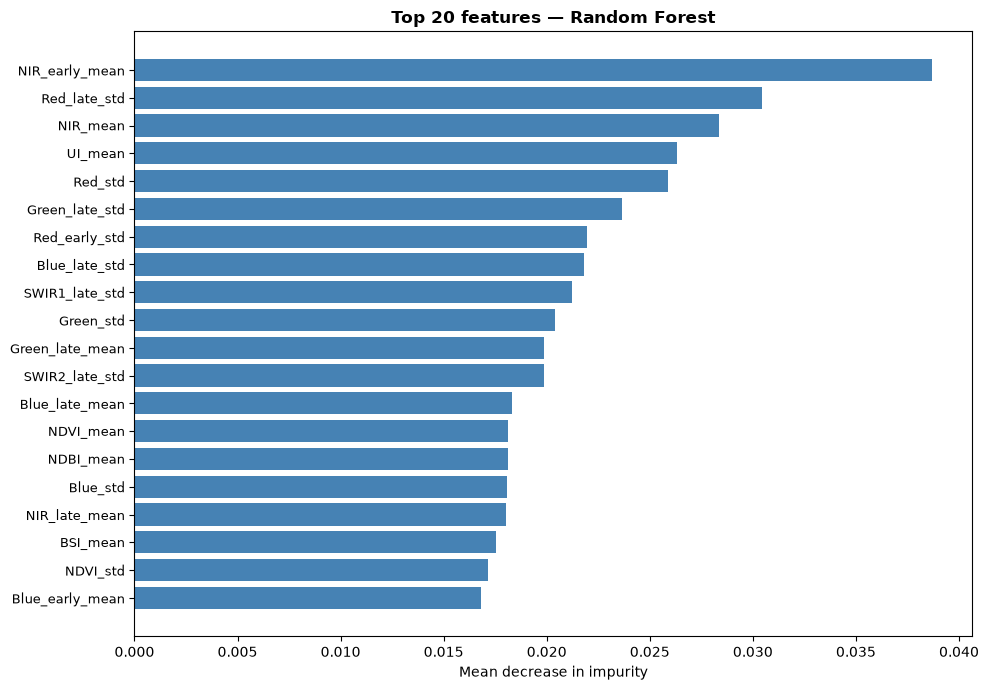

Top 10 features:
   1. NIR_early_mean: 0.0387
   2. Red_late_std: 0.0304
   3. NIR_mean: 0.0284
   4. UI_mean: 0.0263
   5. Red_std: 0.0259
   6. Green_late_std: 0.0236
   7. Red_early_std: 0.0220
   8. Blue_late_std: 0.0218
   9. SWIR1_late_std: 0.0212
  10. Green_std: 0.0204


In [33]:
importances = rf_final.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

TOP_N = 20
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(TOP_N),
        importances[sorted_idx[:TOP_N]][::-1],
        color='steelblue', edgecolor='none')
ax.set_yticks(range(TOP_N))
ax.set_yticklabels([feature_names[i] for i in sorted_idx[:TOP_N]][::-1], fontsize=9)
ax.set_xlabel('Mean decrease in impurity')
ax.set_title(f'Top {TOP_N} features — Random Forest', fontweight='bold')
plt.tight_layout()

plt.savefig(
    "../madrid_top10_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print('Top 10 features:')
for rank, idx in enumerate(sorted_idx[:10]):
    print(f'  {rank+1:2d}. {feature_names[idx]}: {importances[idx]:.4f}')


We see that a large number of features are nearly equal in importance. This is no doubt at least partially due to the high correlation between features.   But it also indicates that the Random Forest may be able to discern differencfes based on complex relationships, that would be difficult for a human to discern.

---

## 4.6 Zero-Shot Transfer to Amsterdam

We apply the Madrid-trained model to all Amsterdam pixels without using any Amsterdam labels.
This establishes the **baseline domain gap**: how much performance we lose when moving to
a city the model has never seen.

In [18]:
# 4.6 Zero-Shot Transfer to Amsterdam
# Safe prediction: NO Amsterdam labels used

# Generate predictions
y_ams_pred_zero = rf_final.predict(X_amsterdam)

# Generate probability estimates
proba_amsterdam_zero = rf_final.predict_proba(X_amsterdam)

# Calculate prediction confidence
confidence_ams = proba_amsterdam_zero.max(axis=1)

# Calculate Shannon entropy
eps = 1e-12

entropy_ams = -(
    proba_amsterdam_zero *
    np.log2(np.clip(proba_amsterdam_zero, eps, 1.0))
).sum(axis=1)

print("Amsterdam zero-shot predictions completed")
print("-" * 50)

print("Number of buildings:", len(y_ams_pred_zero))
print("Probability matrix:", proba_amsterdam_zero.shape)

print(f"Average confidence: {confidence_ams.mean():.4f}")
print(f"Average entropy: {entropy_ams.mean():.4f}")

print("\nPredicted class distribution:")

classes, counts = np.unique(
    y_ams_pred_zero,
    return_counts=True
)

for c, count in zip(classes, counts):
    print(f"Class {c}: {count} buildings")

Amsterdam zero-shot predictions completed
--------------------------------------------------
Number of buildings: 25992
Probability matrix: (25992, 4)
Average confidence: 0.4276
Average entropy: 1.7671

Predicted class distribution:
Class 1: 6895 buildings
Class 2: 14789 buildings
Class 3: 1629 buildings
Class 4: 2679 buildings


In [19]:
import pandas as pd
import numpy as np

# Predict Amsterdam buildings
predictions = rf_final.predict(X_amsterdam)
probabilities = rf_final.predict_proba(X_amsterdam)

# Display first 10 predictions
sample = pd.DataFrame({
    "Building": np.arange(1, 11),
    "Pixel X": pixel_ids_amsterdam[:10, 0],
    "Pixel Y": pixel_ids_amsterdam[:10, 1],
    "Predicted Class": predictions[:10],
    "Confidence": probabilities.max(axis=1)[:10]
})

display(sample)

,Building,Pixel X,Pixel Y,Predicted Class,Confidence
0,1,20600,193589,4,0.688
1,2,20600,193590,4,0.586
2,3,20601,193591,4,0.700
3,4,20601,193593,4,0.518
4,5,20602,193588,4,0.776
5,6,20602,193589,4,0.694
6,7,20602,193592,4,0.684
7,8,20603,193589,4,0.688
8,9,20604,193588,4,0.788
9,10,20605,193589,4,0.758


In [20]:
predictions = rf_final.predict(X_amsterdam)

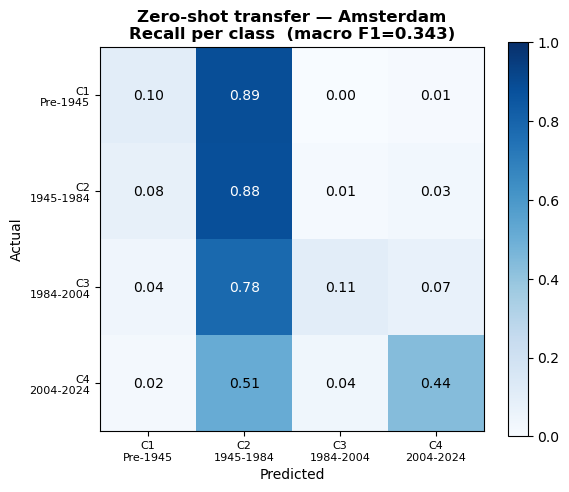

Accuracy is poor for the zero-shot model.  this is to be expected, because buildings in Amsterdam have quite different characteristics from buildings in Madrid. The purpose of the few-shot retraining is to identify Amsterdam-specific clusters within the same metric space. The Amsterdam pixels are then assigned to these recalculated clusters. 

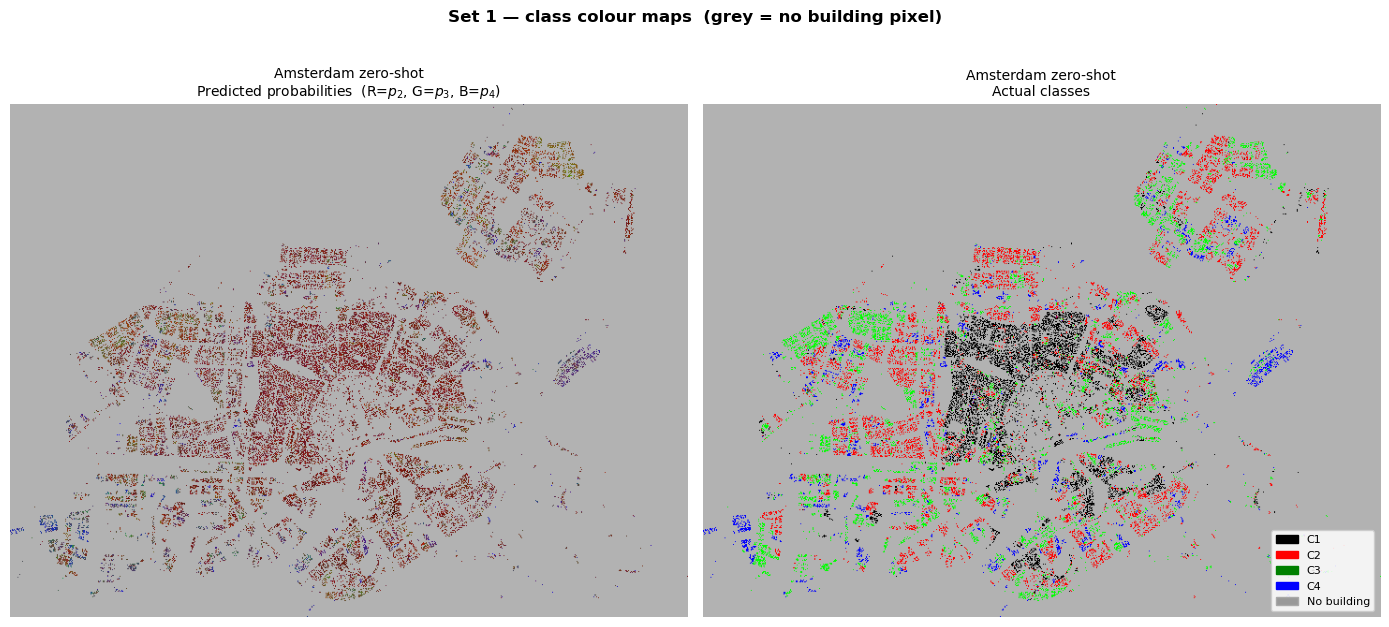

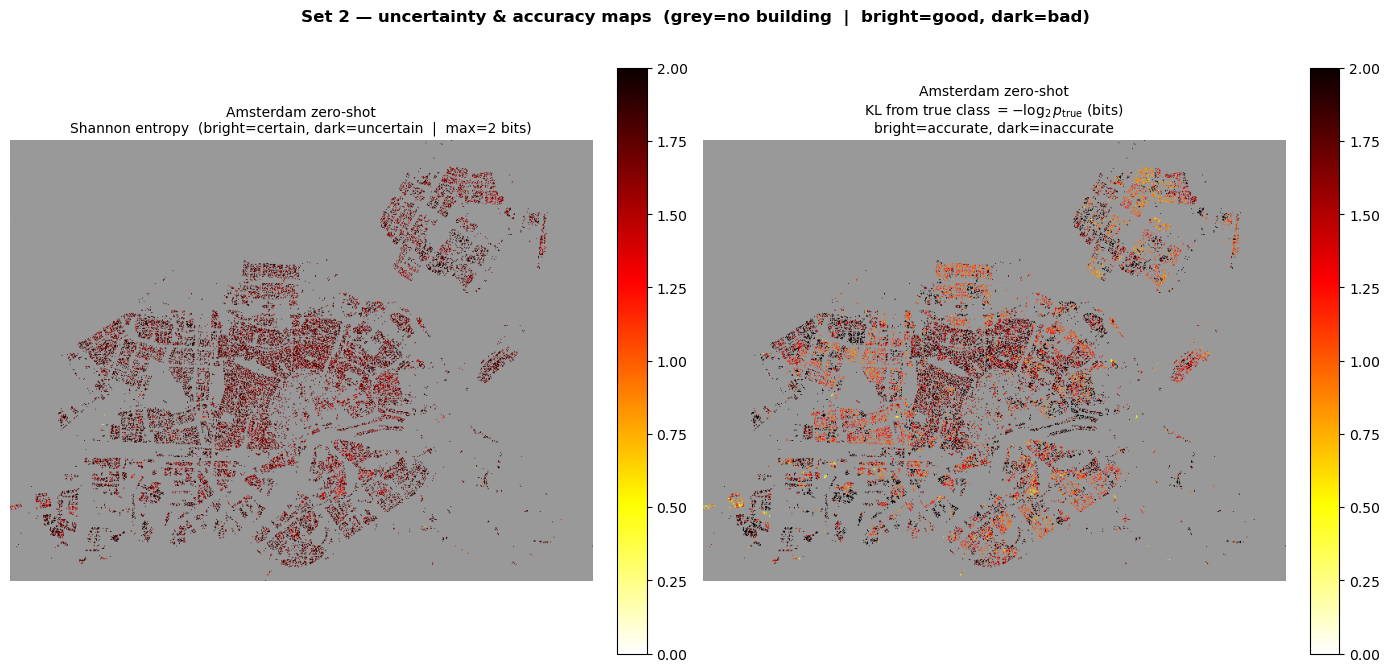

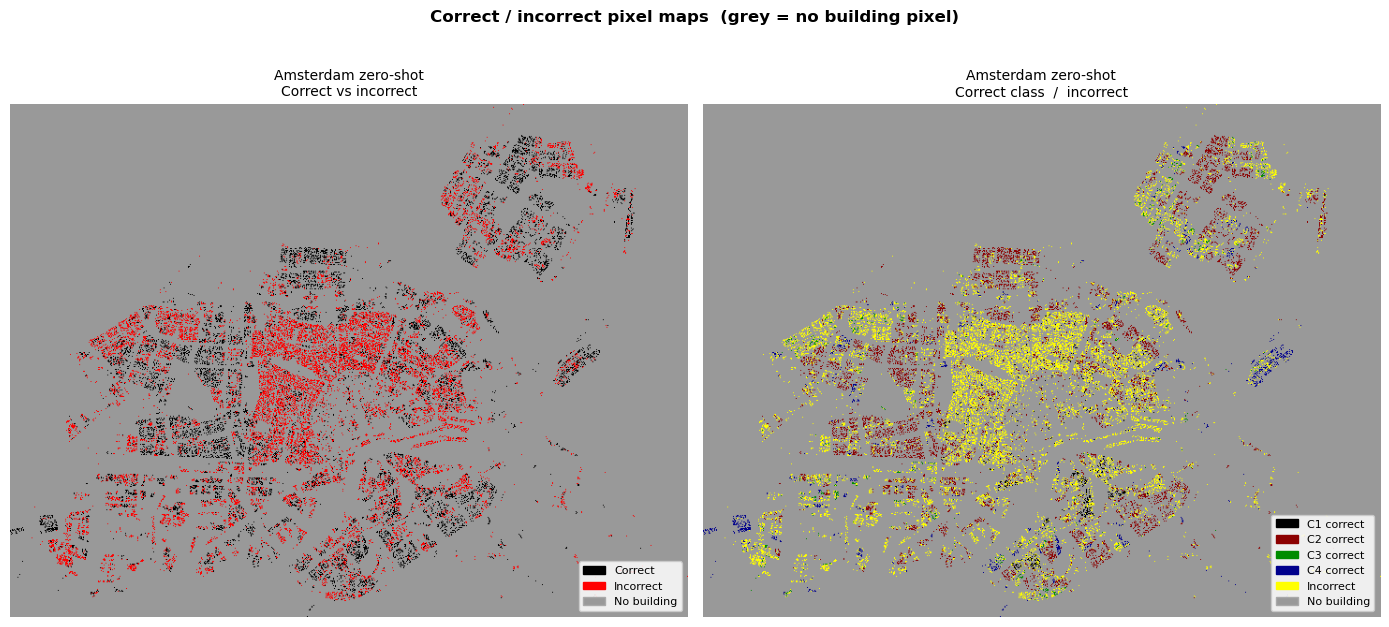

The graphs show clearly that Class 2 is being wildly overpredicted in the zero-shot model.

---

## 4.7 Few-Shot Prototype Transfer

The prototype classifier is the inference step of **prototype networks**, a standard
metric learning technique:

1. For each class, compute the **prototype** = mean feature vector of the labelled examples.
2. Classify unlabelled points by assigning them to the nearest prototype (Euclidean distance).

This is equivalent to 1-NN where the single "neighbour" is a smoothed class representative.
It generalises better than raw k-NN with very few labels because averaging reduces noise.

We run the experiment for several label budgets (samples per class) and repeat each
10 times with different random draws to estimate variance. The resulting plot shows
performance as a function of label budget — the key question for deciding how much
annotation effort Amsterdam requires.

     5 shots/class: macro-F1 = 0.5437 +/- 0.0324
    10 shots/class: macro-F1 = 0.5649 +/- 0.0312
    25 shots/class: macro-F1 = 0.5986 +/- 0.0176
    50 shots/class: macro-F1 = 0.6079 +/- 0.0101
   100 shots/class: macro-F1 = 0.6129 +/- 0.0097
   200 shots/class: macro-F1 = 0.6150 +/- 0.0036


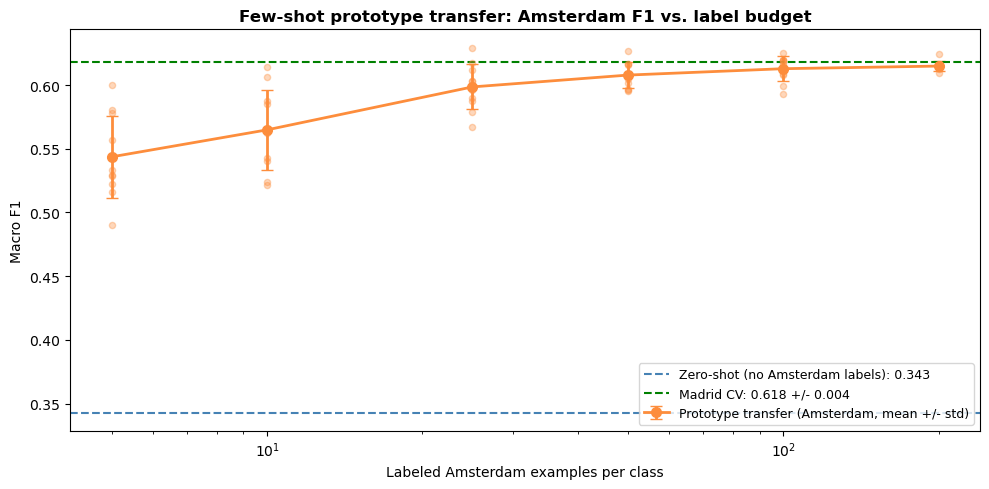

The graph  shows that even with 5 examples per class, a huge boost in accuracy is seen compared to the zero-shot model. As few as 25 samples per class increases by an additional 10%, and 100 samples per class is sufficient to clearly establish the class centers, with additional samples bringing only marginal improvement.

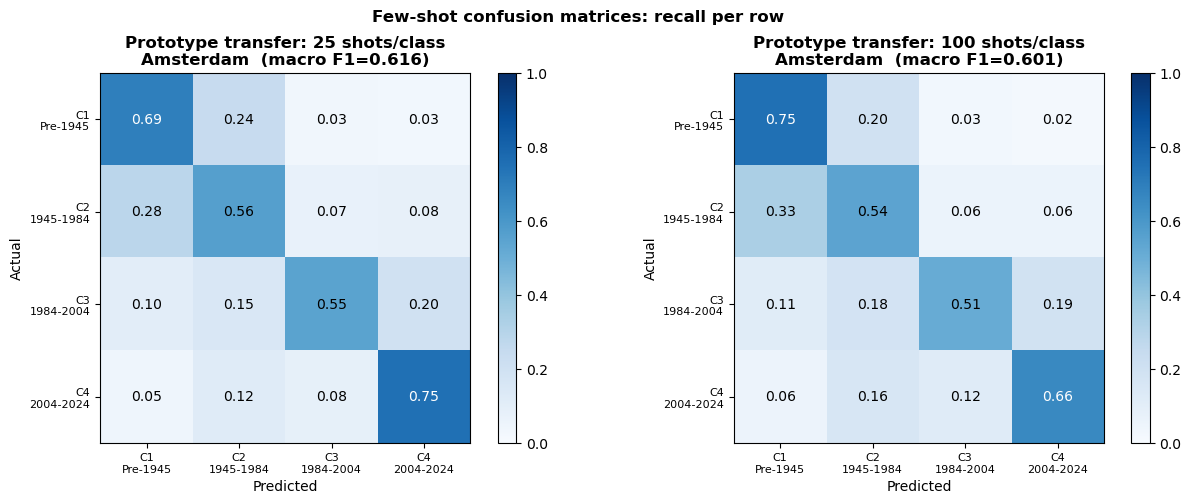

The recall performance for Amsterdam just about matches (and for some classes exceeds!) the recall obtained for Madrid.

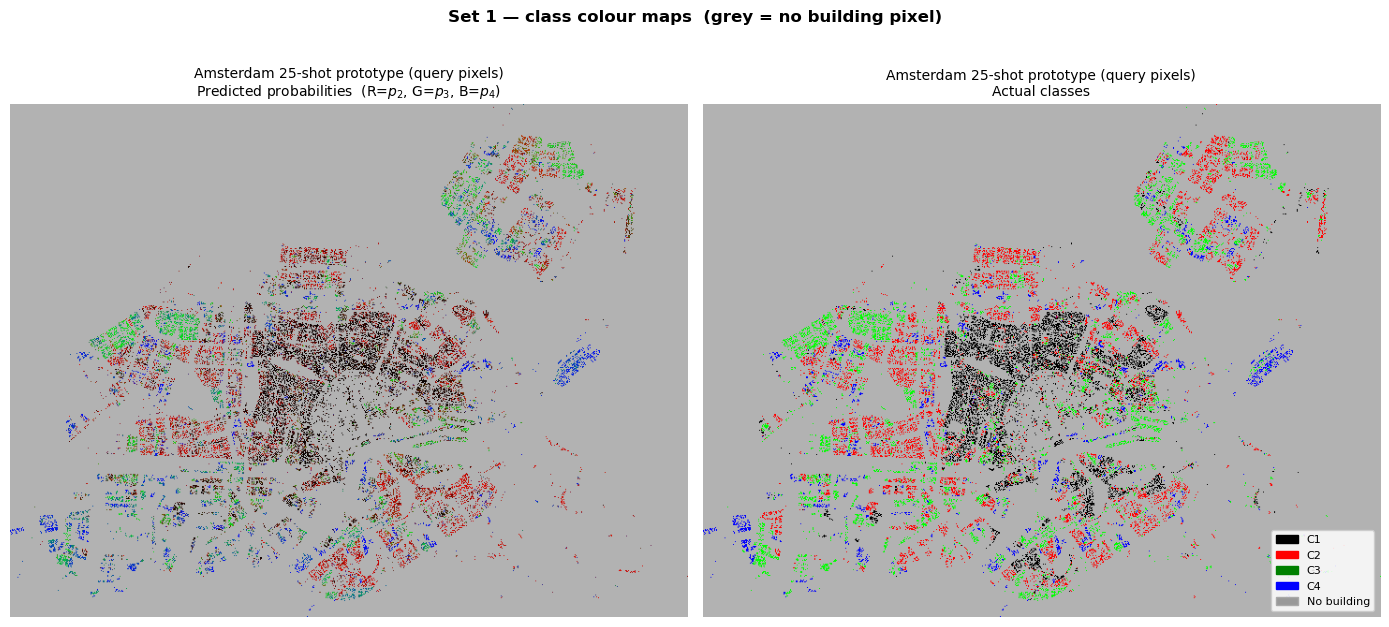

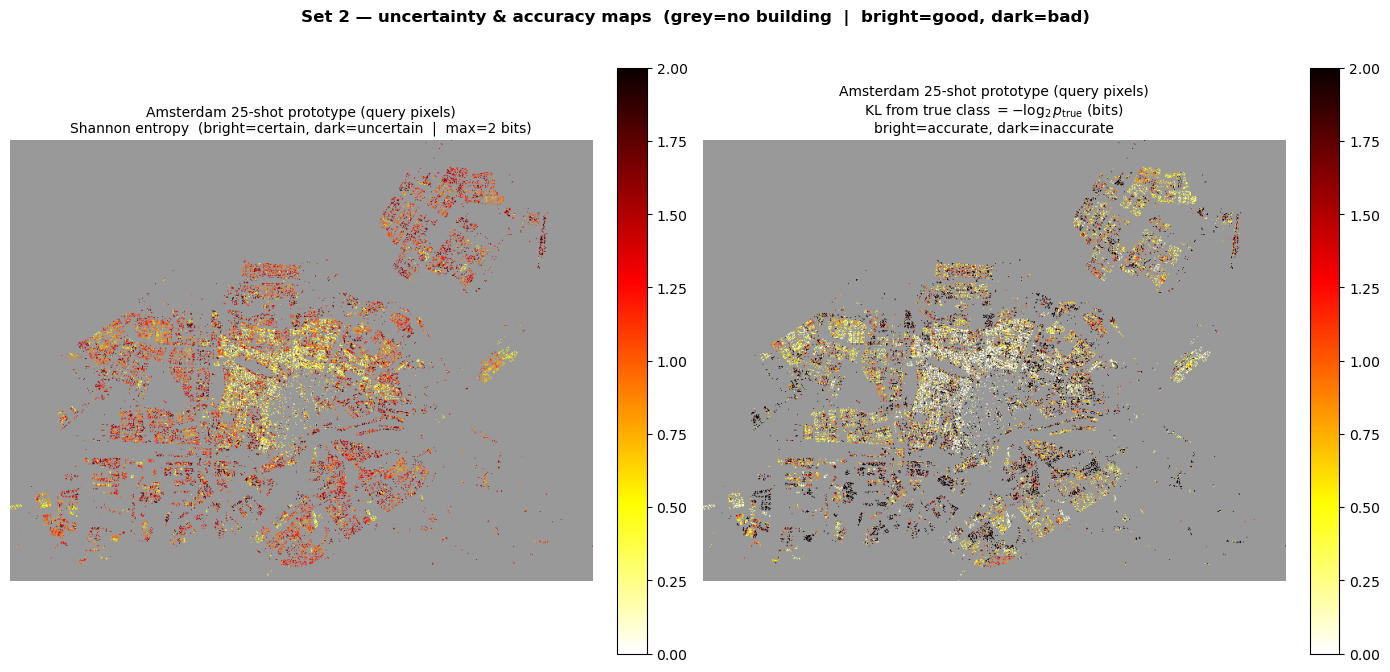

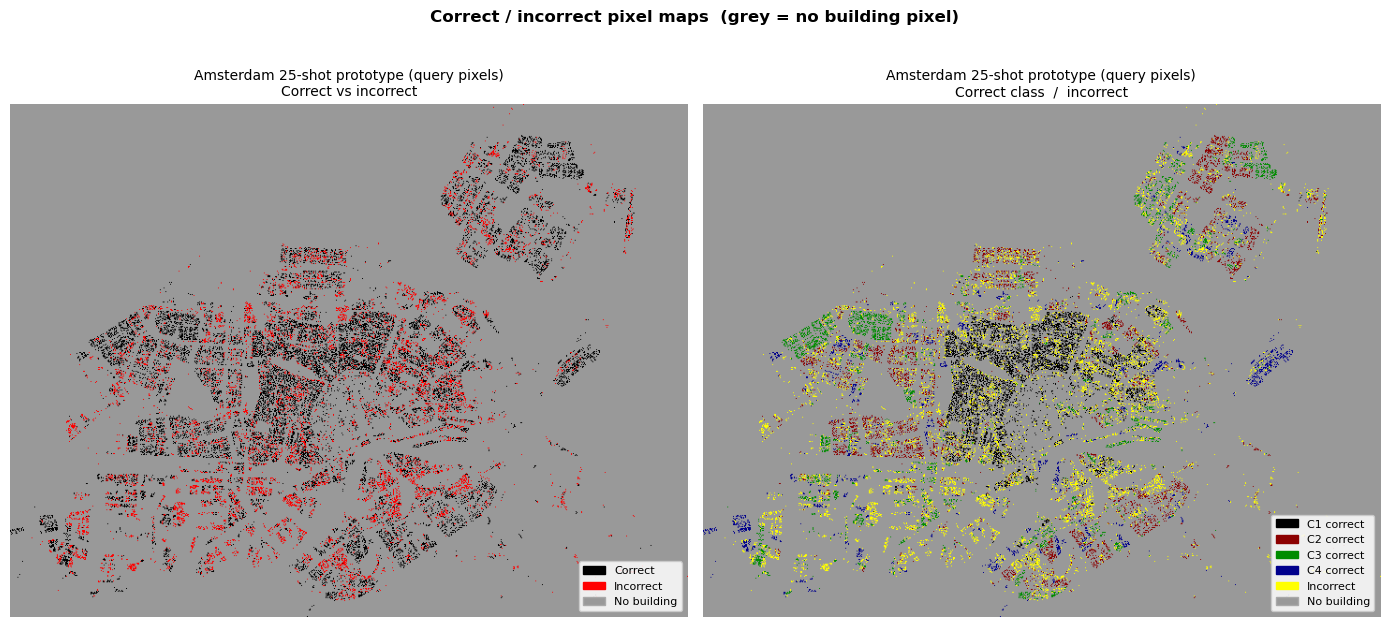

As with Madrid, the model is identifying most local areas where each specific classes predominates. 

---

## 4.8 Summary

**Madrid cross-validation** (5-fold, with error bars) gives the headline performance
estimate. Error bars reveal how stable the estimate is — tight bars mean the result
is reliable; wide bars mean more folds or data are needed.

**Zero-shot transfer** to Amsterdam shows the raw domain gap: how much performance
degrades when moving to a city the model has never seen. A large gap (>0.1 macro F1)
suggests the feature space does not transfer perfectly, which motivates the few-shot step.

**Few-shot prototype transfer** closes the gap progressively as more Amsterdam labels
are added. The prototype classifier is the simplest form of metric learning inference:
- With very few labels (5-10 per class) it may already improve over zero-shot.
- With 100-200 labels per class the gap to the Madrid CV score should largely close.

### Ideas for improvement

(Note these ideas are generated by Claude, and are not guaranteed.  I didn't check them carefully.  Do your own brainstorming!)

**Better feature representation (higher leverage)**
- Per-decade statistics instead of two fixed periods
- Slope of linear trend per band (captures systematic change over time)
- Year of maximum/minimum reflectance per band
- Changepoint detection features: year of largest single-year jump

**Better metric learning**
- Learn an explicit embedding with triplet loss (neural network)
- Use the Madrid-trained RF leaf node assignments as a kernel embedding
  (`rf.apply()` returns leaf IDs; co-occurrence rate is a natural similarity)
- Domain-adversarial training: penalise features that predict city identity

**Better few-shot transfer**
- Fine-tune on Amsterdam labels rather than using prototypes
- Use the Amsterdam unlabelled data for self-training (pseudo-labels from zero-shot)

In [28]:
import numpy as np
import pandas as pd
from pathlib import Path

# Generate predictions using Madrid-trained model
predictions = rf_final.predict(X_amsterdam)

# Convert classes 1-4 to submission classes 0-3
submission_classes = predictions.astype(int) - 1

# Create official submission format
submission = pd.DataFrame({
    "id": np.arange(len(predictions)),
    "class": submission_classes
})

# Validate submission
assert len(submission) == 25992
assert list(submission.columns) == ["id", "class"]
assert submission["id"].iloc[0] == 0
assert submission["id"].iloc[-1] == 25991
assert submission["class"].between(0, 3).all()
assert submission.isnull().sum().sum() == 0

# Save submission
output_path = Path("../submission.csv")
submission.to_csv(output_path, index=False)

print("SUBMISSION CREATED SUCCESSFULLY!")
print("Rows:", len(submission))
print("Columns:", list(submission.columns))
print("Class distribution:")
print(submission["class"].value_counts().sort_index())
print("\nFile:", output_path.resolve())
print("\nFirst 10 rows:")
print(submission.head(10).to_string(index=False))

SUBMISSION CREATED SUCCESSFULLY!
Rows: 25992
Columns: ['id', 'class']
Class distribution:
class
0     6895
1    14789
2     1629
3     2679
Name: count, dtype: int64

File: C:\Users\dell\Desktop\data_hack2\submission.csv

First 10 rows:
 id  class
  0      3
  1      3
  2      3
  3      3
  4      3
  5      3
  6      3
  7      3
  8      3
  9      3


In [29]:
import joblib
from pathlib import Path

model_path = Path("../rf_final_madrid.pkl")

joblib.dump(rf_final, model_path, compress=3)

print("Final model saved successfully!")
print("Model:", model_path.resolve())
print("File size:", round(model_path.stat().st_size / 1024 / 1024, 2), "MB")

Final model saved successfully!
Model: C:\Users\dell\Desktop\data_hack2\rf_final_madrid.pkl
File size: 252.12 MB


In [30]:
import joblib
import numpy as np
import pandas as pd

# Load saved model
saved_model = joblib.load("../rf_final_madrid.pkl")

# Predict Amsterdam again
check_predictions = saved_model.predict(X_amsterdam)

# Convert to submission labels
check_classes = check_predictions.astype(int) - 1

# Load submission
saved_submission = pd.read_csv("../submission.csv")

# Verify consistency
assert len(saved_submission) == 25992
assert np.array_equal(
    check_classes,
    saved_submission["class"].to_numpy()
)

print("FINAL VALIDATION PASSED!")
print("Model loaded successfully.")
print("Predictions match submission.")
print("Total buildings:", len(check_classes))
print("All submission classes:", sorted(saved_submission["class"].unique()))

FINAL VALIDATION PASSED!
Model loaded successfully.
Predictions match submission.
Total buildings: 25992
All submission classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [31]:
import pandas as pd
import numpy as np

# Load submission file
submission = pd.read_csv("../submission.csv")

# Validation checks
assert len(submission) == 25992, "Incorrect number of rows!"
assert list(submission.columns) == ["id", "class"], "Incorrect columns!"

assert submission["id"].is_unique, "Duplicate IDs found!"
assert np.array_equal(
    submission["id"].to_numpy(),
    np.arange(25992)
), "IDs are missing or incorrectly ordered!"

assert submission["class"].notna().all(), "Missing classes!"
assert submission["class"].isin([0, 1, 2, 3]).all(), "Invalid class values!"

print("=" * 45)
print("FINAL SUBMISSION QUALITY CHECK")
print("=" * 45)

print("Rows:", len(submission))
print("Columns:", list(submission.columns))
print("IDs:", submission["id"].min(), "-", submission["id"].max())
print("Missing values:", submission.isnull().sum().sum())

print("\nClass distribution:")
print(submission["class"].value_counts().sort_index())

print("\nALL VALIDATION CHECKS PASSED!")

FINAL SUBMISSION QUALITY CHECK
Rows: 25992
Columns: ['id', 'class']
IDs: 0 - 25991
Missing values: 0

Class distribution:
class
0     6895
1    14789
2     1629
3     2679
Name: count, dtype: int64

ALL VALIDATION CHECKS PASSED!
